# FlowCast Phase 3A Ã¢â‚¬â€ Exploratory Data Analysis

This notebook examines the cleaned and integrated Phase 2 dataset. It is descriptive only: it does not impute values, create an accident-risk target, engineer modelling features, or train models.

In [17]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = ROOT / 'data' / 'processed' / 'flowcast_clean.csv'
FIGURES = ROOT / 'reports' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, parse_dates=['timestamp', 'weather_hour', 'calendar_date'])
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df['hour'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.day_name()
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['day_of_week'] = pd.Categorical(df['day_of_week'], categories=day_order, ordered=True)
print(f'Loaded {DATA_PATH}')
print(f'Shape: {df.shape}')

Loaded c:\Users\lavan\OneDrive\Desktop\FLOWCAST\data\processed\flowcast_clean.csv
Shape: (176701, 38)


## Shape, schema, and sample records

In [18]:
display(df.head())
display(pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(), 'missing_pct': (df.isna().mean() * 100).round(2)}))
print('Columns:', list(df.columns))

,source_row_number,road_id,road_name,latitude,longitude,weather_station_id,date,time,traffic_volume,vehicle_count,...,weather_visibility,weather_weather_condition_original,calendar_date,calendar_public_holiday,calendar_holiday_name,calendar_event_flag,calendar_event_name,calendar_roadwork_flag,hour,day_of_week
0,82178,NL-001,Northline Ave @ 5th,28.643422,77.190411,WS-NORTH,2025-01-01,00:00,97.0,97,...,10000.0,Clear,2025-01-01,1,New Year's Day,0,NaN,0,0,Wednesday
1,90814,NL-001,Northline Ave @ 5th,28.643422,77.190411,WS-NORTH,2025-01-01,00:30,99.0,99,...,10000.0,Clear,2025-01-01,1,New Year's Day,0,NaN,0,0,Wednesday
2,82754,NL-001,Northline Ave @ 5th,28.643422,77.190411,WS-NORTH,2025-01-01,01:00,102.0,102,...,10000.0,Clear,2025-01-01,1,New Year's Day,0,NaN,0,1,Wednesday
3,94802,NL-001,Northline Ave @ 5th,28.643422,77.190411,WS-NORTH,2025-01-01,01:30,113.0,113,...,10000.0,Clear,2025-01-01,1,New Year's Day,0,NaN,0,1,Wednesday
4,142583,NL-001,Northline Ave @ 5th,28.643422,77.190411,WS-NORTH,2025-01-01,02:00,92.0,92,...,10000.0,clear,2025-01-01,1,New Year's Day,0,NaN,0,2,Wednesday


,dtype,missing,missing_pct
source_row_number,int64,0,0.00
road_id,object,0,0.00
road_name,object,0,0.00
latitude,float64,0,0.00
longitude,float64,0,0.00
weather_station_id,object,0,0.00
date,datetime64[ns],0,0.00
time,object,0,0.00
traffic_volume,float64,4587,2.60
vehicle_count,int64,0,0.00


Columns: ['source_row_number', 'road_id', 'road_name', 'latitude', 'longitude', 'weather_station_id', 'date', 'time', 'traffic_volume', 'vehicle_count', 'vehicle_type_dist', 'avg_speed', 'occupancy', 'congestion_level', 'travel_time', 'accident_count', 'signal_timing', 'road_capacity', 'timestamp', 'congestion_level_provenance', 'vc_ratio', 'quality_flags', 'weather_hour', 'weather_date', 'weather_time', 'weather_weather_condition', 'weather_temperature', 'weather_rainfall', 'weather_visibility', 'weather_weather_condition_original', 'calendar_date', 'calendar_public_holiday', 'calendar_holiday_name', 'calendar_event_flag', 'calendar_event_name', 'calendar_roadwork_flag', 'hour', 'day_of_week']


The `quality_flags` and optional calendar name fields are sparse by design. Numeric traffic and weather missingness is retained rather than imputed.

## Traffic coverage by road and timestamp

,rows,first_timestamp,last_timestamp,unique_timestamps,missing_volume
road_id,,,,,
NL-001,7059,2025-01-01,2025-05-31 23:30:00,7059,196
NL-002,7081,2025-01-01,2025-05-31 23:30:00,7081,182
NL-003,7064,2025-01-01,2025-05-31 23:30:00,7064,188
NL-004,7091,2025-01-01,2025-05-31 23:30:00,7091,174
NL-005,7064,2025-01-01,2025-05-31 23:30:00,7064,198
NL-006,7053,2025-01-01,2025-05-31 23:30:00,7053,177
NL-007,7072,2025-01-01,2025-05-31 23:30:00,7072,194
NL-008,7066,2025-01-01,2025-05-31 23:30:00,7066,173
NL-009,7069,2025-01-01,2025-05-31 23:30:00,7069,192


Unique timestamps: 7248
Traffic date range: 2025-01-01 00:00:00 to 2025-05-31 23:30:00


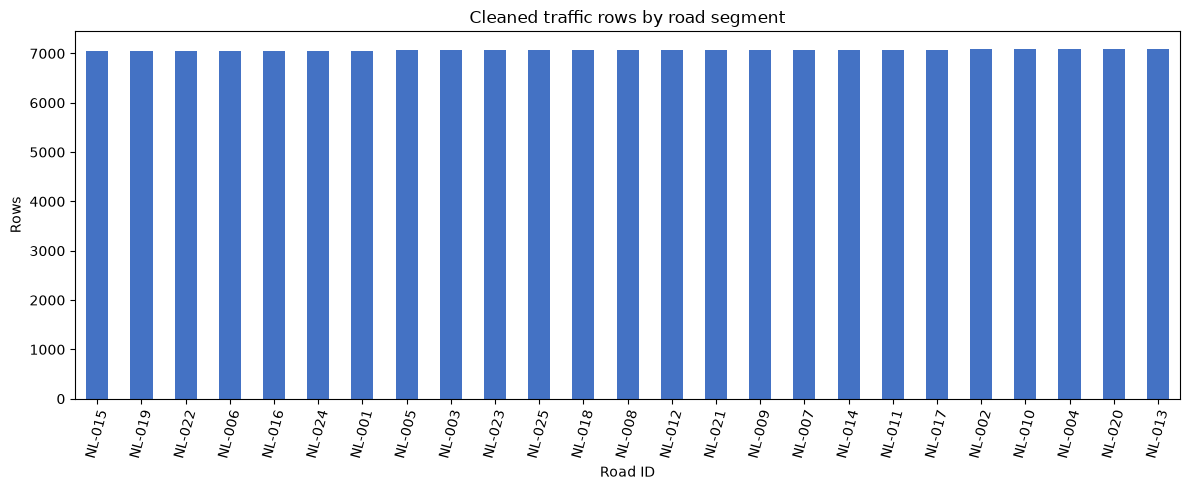

In [19]:
road_coverage = df.groupby('road_id', observed=True).agg(
    rows=('road_id', 'size'),
    first_timestamp=('timestamp', 'min'),
    last_timestamp=('timestamp', 'max'),
    unique_timestamps=('timestamp', 'nunique'),
)
road_coverage['missing_volume'] = df.groupby('road_id', observed=True)['traffic_volume'].apply(lambda s: int(s.isna().sum()))
display(road_coverage.sort_index())
print('Unique timestamps:', df['timestamp'].nunique())
print('Traffic date range:', df['timestamp'].min(), 'to', df['timestamp'].max())

fig, ax = plt.subplots(figsize=(12, 5))
road_coverage['rows'].sort_values().plot.bar(ax=ax, color='#4472C4')
ax.set(title='Cleaned traffic rows by road segment', xlabel='Road ID', ylabel='Rows')
ax.tick_params(axis='x', rotation=75)
fig.tight_layout()
fig.savefig(FIGURES / 'eda_road_coverage.png', dpi=150)
plt.show()

## Traffic-volume, speed, and occupancy distributions

,count,mean,std,min,25%,50%,75%,max
traffic_volume,172114.0,431.290371,283.406664,41.000000,195.000000,362.000000,601.000000,2090.000000
avg_speed,172122.0,42.109956,11.392763,6.700000,36.200000,44.900000,50.900000,64.800000
occupancy,172128.0,31.162687,19.617960,3.000000,14.200000,27.000000,43.700000,100.000000
travel_time,176701.0,3.565617,2.528680,0.800000,2.200000,3.120000,4.090000,29.910000
vc_ratio,172114.0,0.458554,0.286081,0.048752,0.208169,0.400206,0.642951,1.829322


Valid observations used for distributions: {'traffic_volume': 172114, 'avg_speed': 172122, 'occupancy': 172128}


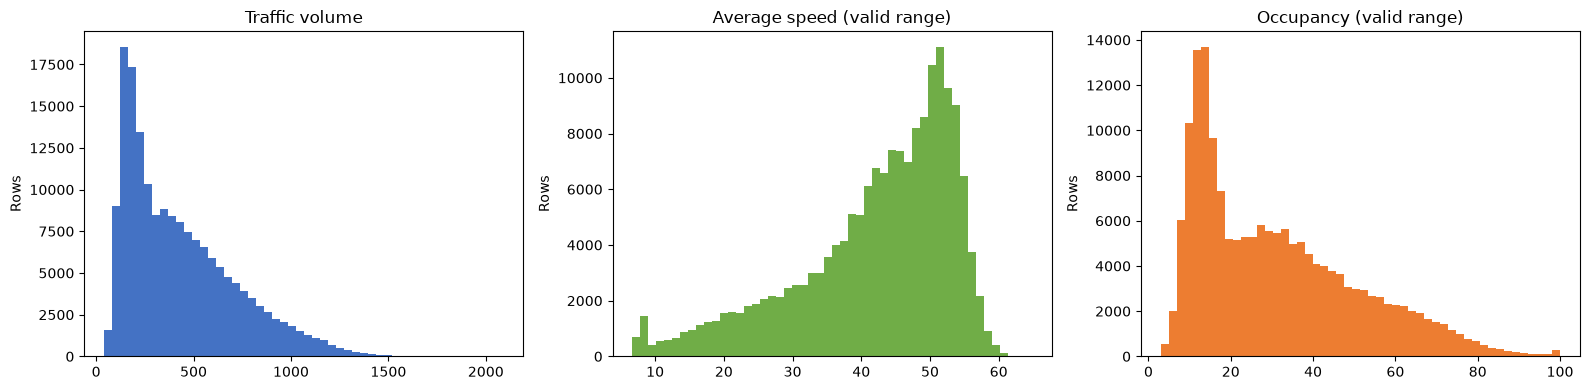

In [20]:
traffic_valid = df['traffic_volume'].dropna()

speed_valid = df.loc[df['avg_speed'].between(0, 200), 'avg_speed'].dropna()

occupancy_valid = df.loc[df['occupancy'].between(0, 100), 'occupancy'].dropna()

summary = df[['traffic_volume', 'avg_speed', 'occupancy', 'travel_time', 'vc_ratio']].describe().T

display(summary)

print('Valid observations used for distributions:', {'traffic_volume': len(traffic_valid), 'avg_speed': len(speed_valid), 'occupancy': len(occupancy_valid)})


fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(traffic_valid, bins=50, color='#4472C4')

axes[0].set_title('Traffic volume')

axes[1].hist(speed_valid, bins=50, color='#70AD47')

axes[1].set_title('Average speed (valid range)')

axes[2].hist(occupancy_valid, bins=50, color='#ED7D31')

axes[2].set_title('Occupancy (valid range)')

for ax in axes:

    ax.set_ylabel('Rows')

fig.tight_layout()

fig.savefig(FIGURES / 'eda_measurement_distributions.png', dpi=150)

plt.show()

The valid-range filters above are descriptive safeguards, not new cleaning rules: Phase 2 already quarantined invalid traffic measurements and retained missing values.

## Congestion levels and imbalance

,count,percent
congestion_level,,
Free-flow,108139,61.20
Moderate,41905,23.72
Heavy,16257,9.20
Severe,9719,5.50
Missing,681,0.39


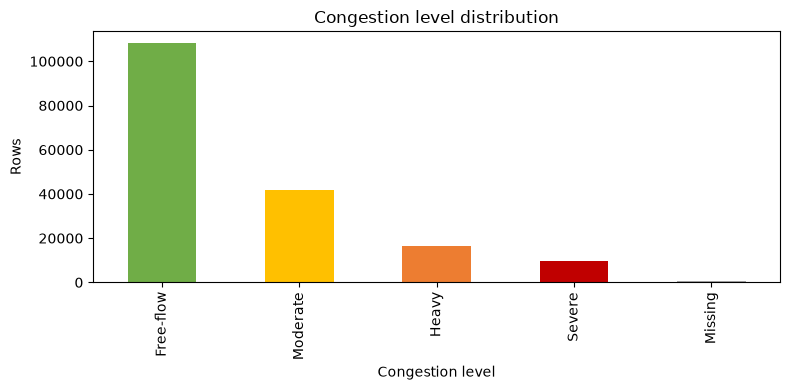

In [21]:
congestion_counts = df['congestion_level'].fillna('Missing').value_counts()
congestion_pct = (congestion_counts / len(df) * 100).round(2)
display(pd.DataFrame({'count': congestion_counts, 'percent': congestion_pct}))

fig, ax = plt.subplots(figsize=(8, 4))
congestion_counts.plot.bar(ax=ax, color=['#70AD47', '#FFC000', '#ED7D31', '#C00000', '#A5A5A5'])
ax.set(title='Congestion level distribution', xlabel='Congestion level', ylabel='Rows')
fig.tight_layout()
fig.savefig(FIGURES / 'eda_congestion_distribution.png', dpi=150)
plt.show()

## Hour-of-day and day-of-week patterns

,mean_volume,median_volume,mean_speed
hour,,,
0,162.232804,157.0,51.975299
1,162.414821,158.0,51.825558
2,163.660322,158.0,51.854680
3,166.109939,160.0,51.750673
4,173.557290,166.0,51.427330
5,210.052763,201.0,50.406344
6,345.187334,330.0,46.399512
7,630.678905,609.0,34.747989
8,886.152049,869.0,21.909667


,mean_volume,median_volume,mean_speed
day_of_week,,,
Monday,483.844278,415.0,39.861638
Tuesday,474.157857,409.0,40.174730
Wednesday,446.988399,379.0,41.277346
Thursday,474.136994,408.0,40.143990
Friday,482.489850,416.0,40.290281
Saturday,325.565313,277.0,46.603133
Sunday,331.230222,279.0,46.446273


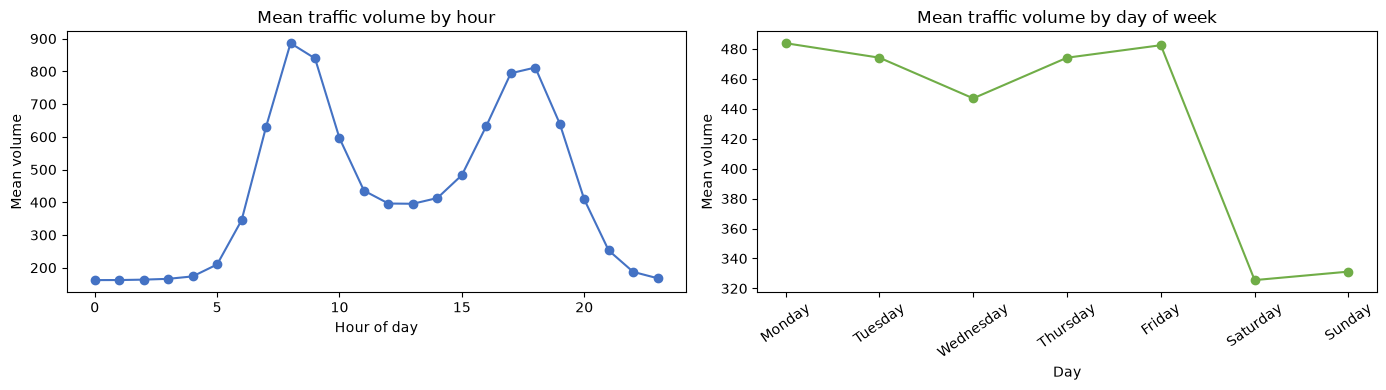

In [22]:
hourly = df.groupby('hour', observed=True).agg(mean_volume=('traffic_volume', 'mean'), median_volume=('traffic_volume', 'median'), mean_speed=('avg_speed', 'mean'))
weekly = df.groupby('day_of_week', observed=True).agg(mean_volume=('traffic_volume', 'mean'), median_volume=('traffic_volume', 'median'), mean_speed=('avg_speed', 'mean'))
display(hourly)
display(weekly)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
hourly['mean_volume'].plot(ax=axes[0], marker='o', color='#4472C4')
axes[0].set(title='Mean traffic volume by hour', xlabel='Hour of day', ylabel='Mean volume')
weekly['mean_volume'].plot(ax=axes[1], marker='o', color='#70AD47')
axes[1].set(title='Mean traffic volume by day of week', xlabel='Day', ylabel='Mean volume')
axes[1].tick_params(axis='x', rotation=35)
fig.tight_layout()
fig.savefig(FIGURES / 'eda_temporal_patterns.png', dpi=150)
plt.show()

## Traffic-volume trend over time

,mean,median,count
timestamp,,,
2025-01-01,266.040280,229.0,1142
2025-01-02,481.412544,414.5,1132
2025-01-03,484.466087,416.5,1150
2025-01-04,348.694273,301.0,1135
2025-01-05,349.779646,304.0,1130


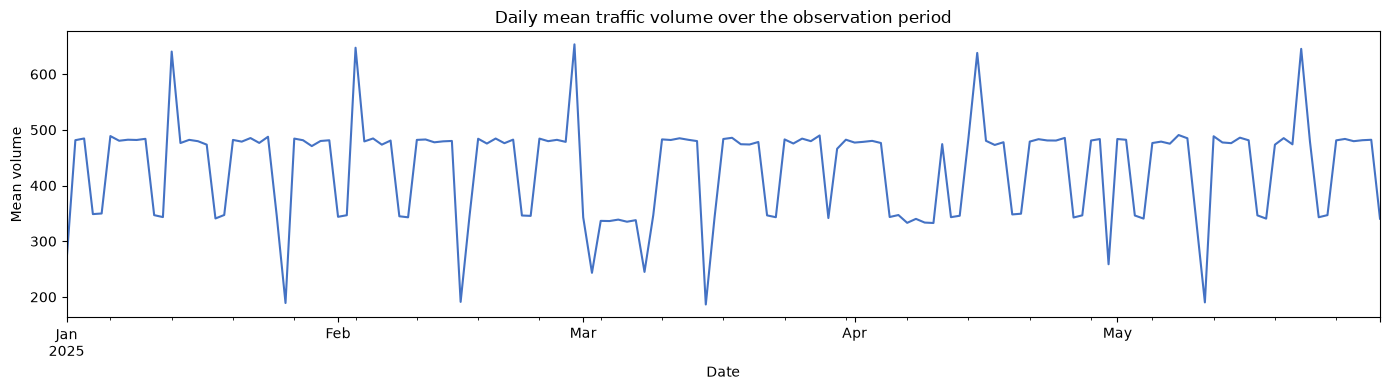

In [23]:
daily = df.set_index('timestamp').resample('D')['traffic_volume'].agg(['mean', 'median', 'count'])
display(daily.head())
fig, ax = plt.subplots(figsize=(14, 4))
daily['mean'].plot(ax=ax, color='#4472C4')
ax.set(title='Daily mean traffic volume over the observation period', xlabel='Date', ylabel='Mean volume')
fig.tight_layout()
fig.savefig(FIGURES / 'eda_daily_volume_trend.png', dpi=150)
plt.show()

## Relationships among traffic, weather, and congestion

,traffic_volume,avg_speed,occupancy,weather_temperature,weather_rainfall,weather_visibility,vc_ratio
traffic_volume,1.000,-0.896,0.938,0.386,-0.038,0.073,0.949
avg_speed,-0.896,1.000,-0.934,-0.341,-0.032,0.015,-0.945
occupancy,0.938,-0.934,1.000,0.404,-0.038,0.074,0.989
weather_temperature,0.386,-0.341,0.404,1.000,0.013,0.030,0.407
weather_rainfall,-0.038,-0.032,-0.038,0.013,1.000,-0.759,-0.038
weather_visibility,0.073,0.015,0.074,0.030,-0.759,1.000,0.074
vc_ratio,0.949,-0.945,0.989,0.407,-0.038,0.074,1.000


,rows,mean_volume,mean_speed,mean_occupancy,mean_rainfall
weather_weather_condition,,,,,
Clear,132715,437.266351,42.073989,31.559764,0.00000
Cloudy,29926,430.245948,42.397971,31.198798,0.00000
Rain,6959,367.825805,40.238902,26.782068,4.84173
Overcast,5853,422.001752,42.980721,30.430361,0.00000
Fog,1248,217.882305,45.376359,15.955218,0.13734


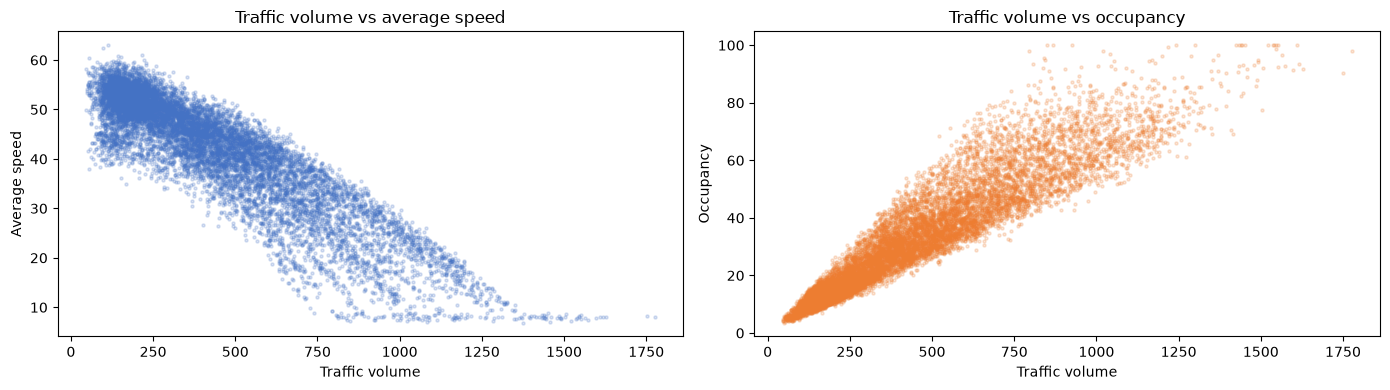

congestion_level,Free-flow,Heavy,Missing,Moderate,Severe
weather_weather_condition,,,,,
Clear,0.603,0.095,0.004,0.239,0.059
Cloudy,0.612,0.093,0.004,0.242,0.050
Fog,0.941,0.002,0.006,0.052,0.000
Overcast,0.643,0.079,0.004,0.223,0.051
Rain,0.692,0.065,0.005,0.230,0.008


In [24]:
numeric = ['traffic_volume', 'avg_speed', 'occupancy', 'weather_temperature', 'weather_rainfall', 'weather_visibility', 'vc_ratio']
display(df[numeric].corr(min_periods=100).round(3))

weather_summary = df.groupby('weather_weather_condition', observed=True).agg(
    rows=('road_id', 'size'), mean_volume=('traffic_volume', 'mean'), mean_speed=('avg_speed', 'mean'), mean_occupancy=('occupancy', 'mean'), mean_rainfall=('weather_rainfall', 'mean')
).sort_values('rows', ascending=False)
display(weather_summary)

sample = df.dropna(subset=['traffic_volume', 'avg_speed', 'occupancy']).sample(min(12000, df.dropna(subset=['traffic_volume', 'avg_speed', 'occupancy']).shape[0]), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].scatter(sample['traffic_volume'], sample['avg_speed'], s=5, alpha=0.2, color='#4472C4')
axes[0].set(title='Traffic volume vs average speed', xlabel='Traffic volume', ylabel='Average speed')
axes[1].scatter(sample['traffic_volume'], sample['occupancy'], s=5, alpha=0.2, color='#ED7D31')
axes[1].set(title='Traffic volume vs occupancy', xlabel='Traffic volume', ylabel='Occupancy')
fig.tight_layout()
fig.savefig(FIGURES / 'eda_measurement_relationships.png', dpi=150)
plt.show()

congestion_weather = pd.crosstab(df['weather_weather_condition'].fillna('Missing'), df['congestion_level'].fillna('Missing'), normalize='index').round(3)
display(congestion_weather)

## EDA conclusions and limitations

The tables and figures above are the source of the findings in `reports/eda_findings.md`. Correlations and group differences are descriptive associations only; they do not establish causal effects. The integrated data contains missing traffic measurements, missing weather measurements, sparse calendar names, absent traffic windows, and a strong imbalance in congestion labels. Feature engineering should preserve missingness indicators, treat time-of-day and day-of-week as explicit temporal predictors, and avoid leakage from future observations. No modelling or accident-risk target is created in this phase.